In [1]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #                         
#     Maurice F. Huguenin, m.huguenin-virchaux@unsw.edu.au, 26. 01. 2024      #                                                
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #
# % preamble ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ #                         
base = '/g/data/e14/mv7494/access-om2/archive/025deg_jra55_iaf/'
save = '/gxfs_home/geomar/smomw723/EddiesHC_figures/'

import xarray as xr # for working with labelled multi-dimensional arrays                                                                
import numpy as np # for numerical operations                                                           
import string # for subplot annotation
import matplotlib.pyplot as plt # for matlab-like plotting                                              
from matplotlib.patches import Rectangle # for shaded rectangle
import cartopy.crs as ccrs # for maps     
from matplotlib import gridspec
import matplotlib as mpl
#from cdo import *
#cdo = Cdo()
import os
import sys
import string # for subplot annotation
import scipy
import warnings
import cmocean as cm
#from wrf import to_np # conversion to arrays required for arrows on maps    
import tarfile as tf
import io
from scipy.stats import linregress
from datetime import datetime
import cftime

import matplotlib.patheffects as PathEffects
warnings.filterwarnings('ignore') # suppress warnings
from matplotlib import ticker
import nc_time_axis
import time
import cftime
import cartopy.mpl.ticker as cticker
import string # for subplot annotation
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


#from dask.distributed import Client
#client = Client(n_workers=16)         # careful: do not run with 48 workers here as it will crash
#client = Client(n_workers=8, threads_per_worker=4)
#client
rotblau = [[0.4 , 0.  , 0.12], [0.47, 0.02, 0.13], [0.62, 0.07, 0.16], [0.66, 0.16, 0.2],
           [0.8 , 0.3 , 0.27], [0.87, 0.44, 0.35], [0.93, 0.58, 0.45], [0.96, 0.7 , 0.58], 
           [0.98, 0.8 , 0.71], [0.98, 0.94, 0.92], [0.93, 0.95, 0.96], [0.85, 0.91, 0.95],
           [0.76, 0.87, 0.93], [0.64, 0.8 , 0.89], [0.49, 0.72, 0.84], [0.34, 0.62, 0.79], 
           [0.23, 0.53, 0.74], [0.16, 0.44, 0.7] , [0.1 ,0.35, 0.6], [0.05, 0.24, 0.45], [0.02, 0.19, 0.38]]

/gxfs_home/geomar/smomw723/miniforge3/envs/py3_std/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


### Open the EBUS masks

Text(0.5, 1.0, 'The four EBUS masks: California, Canada, Benguela and Peru')

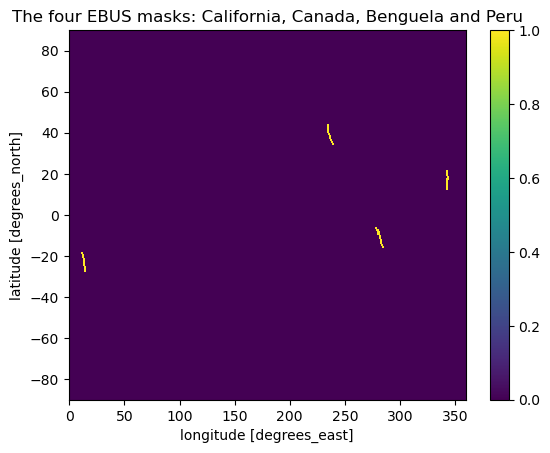

In [2]:
masks_all = xr.open_dataset("/gxfs_home/geomar/smomw447/EBUS/data/EBUS_masks/EBUS_masks_all_r360x180.nc")
masks_all = masks_all.where(masks_all != 0)
(masks_all.mask_cal.fillna(0) + masks_all.mask_can.fillna(0) + masks_all.mask_ben.fillna(0) + masks_all.mask_per.fillna(0)).plot()
plt.title('The four EBUS masks: California, Canada, Benguela and Peru')

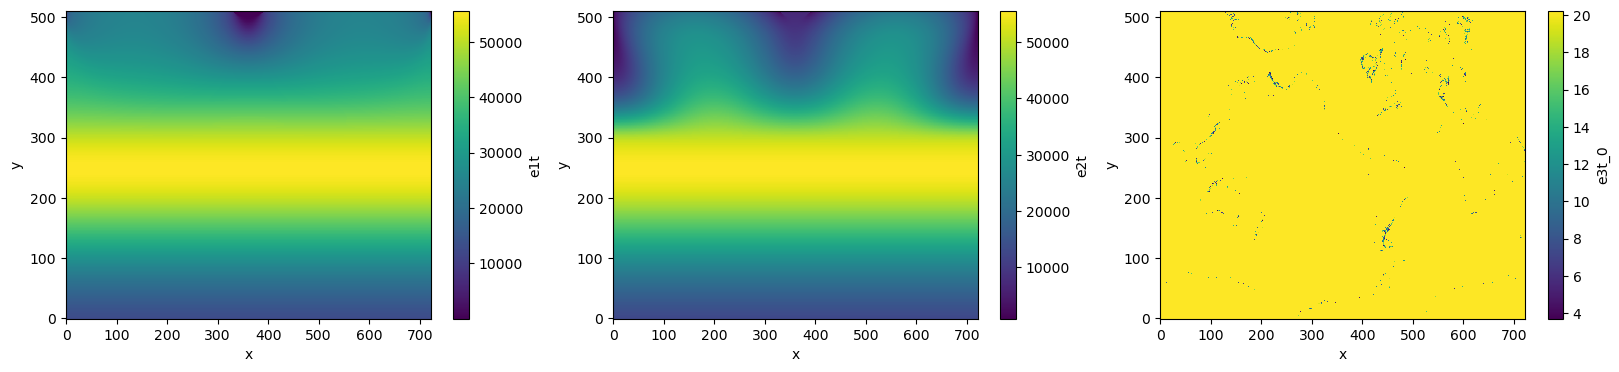

In [3]:
vars = ['votemper']
fn   = ['_grid_T']
freq = ['_1m_', '_1y_']

# ocean grid cell area [m2]
mesh_mask = xr.open_mfdataset('/gxfs_home/geomar/smomw723/EddiesHC_data/mesh_mask.nc')
# create empty 180x360 mesh grid where I put in data from e1t, e2t, e3t
plt.figure(figsize=(20,4)); plt.subplot(1,3,1); mesh_mask.e1t.plot(); plt.subplot(1,3,2); mesh_mask.e2t.plot(); plt.subplot(1,3,3); mesh_mask.e3t_0.squeeze()[10,:,:].plot()

# prepare depth array for weighting
deptht_for_weighted = mesh_mask.e3t_0.squeeze()[:,150,100].rename({'z': 'deptht'}) # 'e3t_0' (deptht: 46)
area_weighting      = mesh_mask.e1t * mesh_mask.e2t

### Postprocessing OHC data
- done via the shell script /gxfs_work/geomar/smomw723/EddiesHC_analysis/EBUS_project/multiply_masks.sh
- which multiplies the masks of the four EBUS regions with the original data (so it's less big)
- then it removes superfluous longitude and latitude bands that only have NAN values

In [4]:
%%time
#area_t = (area_t.e1t*area_t.e2t).squeeze()
#area_t

rho_0 = 1025.022            # global ocean reference density of sea water used in FOCI-MOPS [kg m^{-3}]
C_p   = 3992.10322329649    # global ocean average specific heat capacity [J kg^{-1} K^{-1}]
vars_to_sum = ['ttrd_xad', 'ttrd_yad', 'ttrd_zad', 'ttrd_ldf', 'ttrd_zdf', 'ttrd_qns', 'ttrd_qsr']

dataset = ['time_series', 'depth_integrated', 'full']
maske = ['california', 'canary', 'benguela', 'peru']

for t in range(1): # loop through the monthly or yearly frequency
    for s in range(1): # loop through the three data sets: time_series, depth_integrated and full
        for f in range(4): # loop through the four EBUS regions: California, Canary Islands, Benguela and Peru
            # if file already exists, skip this iteration of the loop
            if os.path.exists('/gxfs_work/geomar/smomw723/' + 'EddiesHC_analysis/EBUS_project/'+'MLT_budget_EBUS_region_'+maske[f]+'_'+dataset[s]+'.nc'):
                print('MLT budget for ' + dataset[s] + ', ' + maske[f] + ' already done')
                continue
            else:           
                print('closing MLT budget for ' + dataset[s] + ', ' + maske[f])
    
                ds_OHC = xr.open_mfdataset('/gxfs_work/geomar/smomw723/EddiesHC_analysis/EBUS_project/'+'output_'+maske[f][:3]+'_grid_OHC.nc')
                ds_T = xr.open_mfdataset('/gxfs_work/geomar/smomw723/EddiesHC_analysis/EBUS_project/'+'output_'+maske[f][:3]+'_grid_T.nc')
    
                # loading in mixed layer depth as monthly average and instantaneous (snapshot) fields
                somxl010 = ds_T.somxl010
                somxl010inst = ds_OHC.somxl010inst
    
                # calculate the left hand side mixed layer temperature tendency
    #            dMLTdt_lhs = (ds_OHC.where(ds_OHC.deptht <= somxl010inst).tempinst.diff('time_counter') * masks_all[maske[f]])
                # select mask first to reduce computational time
                dMLTdt_lhs = (ds_OHC.tempinst.where(ds_OHC.deptht <= somxl010inst).diff('time_counter'))
        
                # select only variable above mixed layer depth, mask for the Eastern Boundary Upwelling System and select only time steps 1:-1 as for the lhs I need to xr.diff() and lose one data point
                MLT_xad    = (ds_OHC[vars_to_sum[0]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5)) # zonal advection of ocean temperature [°C s-1]
                MLT_yad    = (ds_OHC[vars_to_sum[1]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5)) # meridional advection [°C s-1]
                MLT_zad    = (ds_OHC[vars_to_sum[2]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5)) # vertical advection [°C s-1]
                
                MLT_ldf    = (ds_OHC[vars_to_sum[3]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5)) # lateral diffusion [°C s-1]
                MLT_zdf    = (ds_OHC[vars_to_sum[4]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5)) # vertical diffusion [°C s-1]
            
                MLT_qns    = (ds_OHC[vars_to_sum[5]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5)) # non-solar radiative flux [°C s-1]
                MLT_qsr    = (ds_OHC[vars_to_sum[6]].where(ds_OHC.deptht <= somxl010).isel(time_counter=slice(1, None)) * (60*60*24*30.5))  # solar radiative flux [°C s-1]

                sum_rhs = MLT_xad + MLT_yad + MLT_zad + MLT_ldf + MLT_zdf + MLT_qns + MLT_qsr
                # load the data, assign variables and save into a netcdf file
                if dataset[s] == 'time_series':
                    MLT_manual = xr.Dataset({'dMLTdt_lhs': dMLTdt_lhs.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'sum_rhs':    sum_rhs.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'MLT_xad':    MLT_xad.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'MLT_yad':    MLT_yad.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'MLT_zad':    MLT_zad.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                
                                             'MLT_ldf':    MLT_ldf.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'MLT_zdf':    MLT_zdf.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                
                                             'MLT_qns':    MLT_qns.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'MLT_qsr':    MLT_qsr.weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon']),
                                             'MLT_res':    (dMLTdt_lhs - (MLT_xad+MLT_yad+MLT_zad + MLT_ldf+MLT_zdf + MLT_qns+MLT_qsr)).weighted(deptht_for_weighted).mean(['deptht', 'lat', 'lon'])})     
    
                # add attributes for good metadata
                MLT_manual.attrs = {
                    'Author': 'Maurice F. Huguenin', 
                    'Affiliation': 'GEOMAR Helmholtz Centre for Ocean Research Kiel',
                    'Project': 'DFG project CHOICE: Ocean heat and carbon storage under ambitious emission mitigation',
                    'Data set': 'FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets global ' + dataset[s] +
                    ' mixed layer temperature budget for region' + maske[f] + ' with ' + freq[t] + ' frequency',
                    'Unit': '[°C s-1]',
                    'Created': datetime.today().strftime('%Y-%m-%d'),
                    'Mail': 'mhuguenin-virchaux@geomar.de', 
                    'Funding': 'DFG funding code 538865427'}
                MLT_manual.to_netcdf('/gxfs_work/geomar/smomw723/' + 'EddiesHC_analysis/EBUS_project/'+'MLT_budget_EBUS_region_'+maske[f]+'_'+dataset[s]+'.nc', engine='netcdf4') 
        
                # close open datasets
                MLT_manual.close()
                
                # delete large objects
    #            del (ds_OHC, ds_T, MLT_xad, MLT_yad, MLT_zad, MLT_ldf, MLT_zdf, MLT_qns, MLT_qsr, dMLTdt_lhs, MLT_manual)
    # Wall time: 2min 12s
    # FINALLY!!!

MLT budget for time_series, california already done
MLT budget for time_series, canary already done
MLT budget for time_series, benguela already done
MLT budget for time_series, peru already done
CPU times: user 1.75 ms, sys: 192 μs, total: 1.94 ms
Wall time: 5.73 ms


CPU times: user 19.9 s, sys: 403 ms, total: 20.3 s
Wall time: 20.2 s


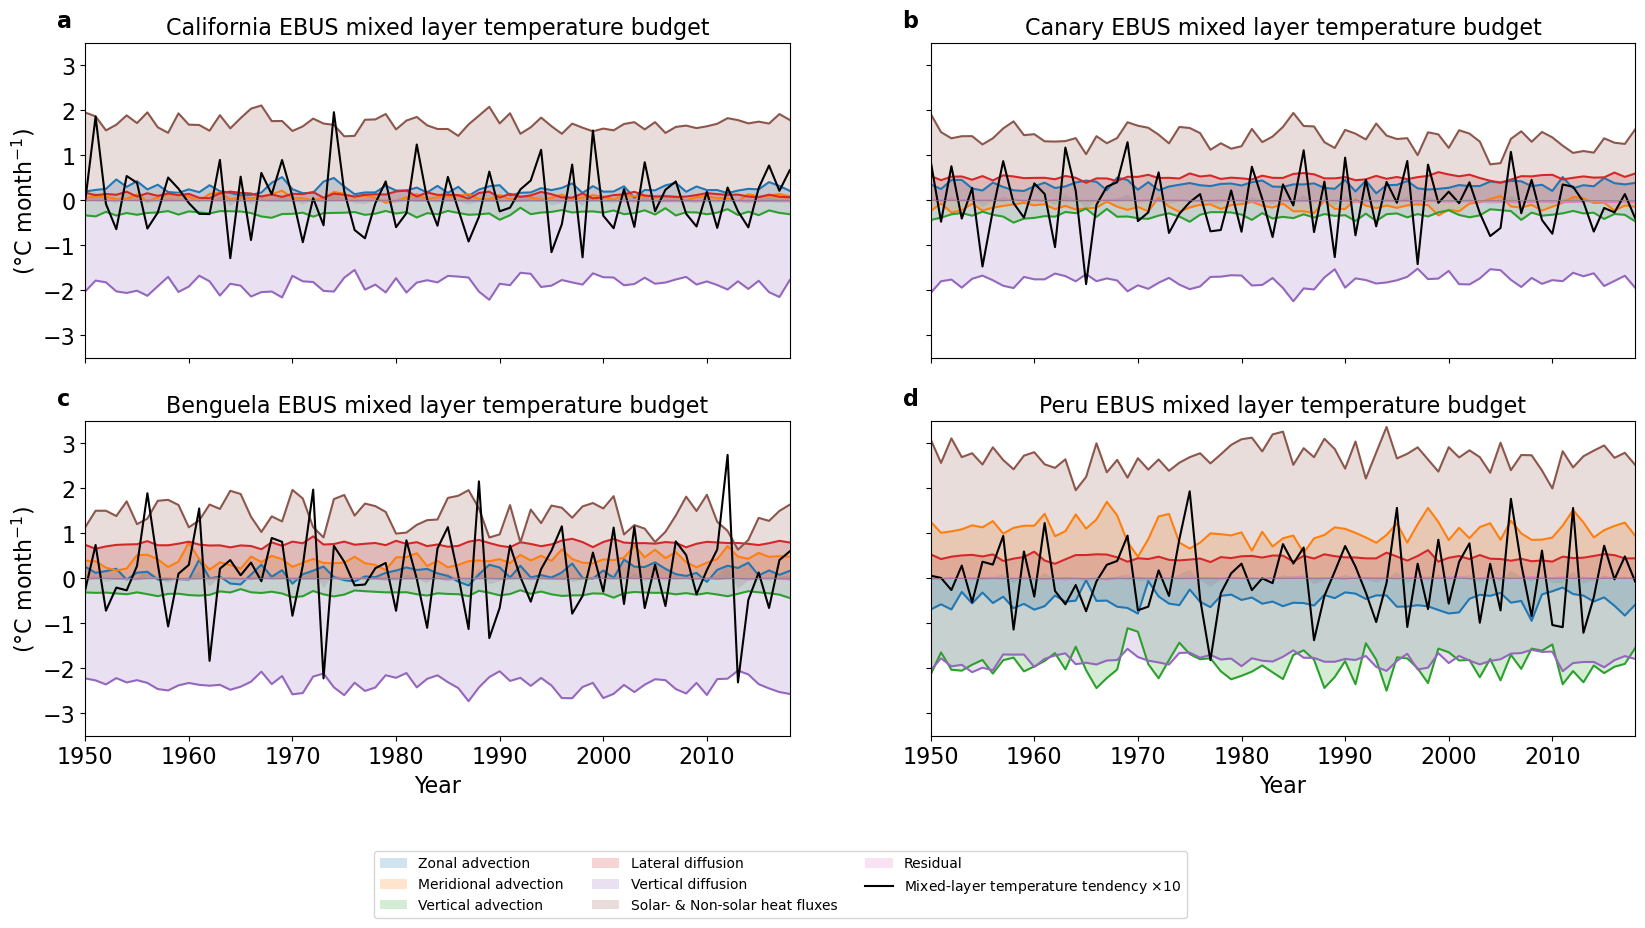

In [5]:
%%time 
maske       = ['california', 'canary', 'benguela', 'peru', 'global']
maske_title = ['California', 'Canary', 'Benguela', 'Peru', 'Global']

vars = ['dMLTdt_lhs', 'sum_rhs', 
        'MLT_xad', 'MLT_yad', 'MLT_zad', 
        'MLT_ldf', 'MLT_zdf', 
        'MLT_qns', 'MLT_qsr', 
        'MLT_res']
fill_colours = ['#90BC59', '#328ECA', '#FF8753', '#9858A5', '#F1C14D', 'k']
var_labels = ['Mixed-layer temperature tendency', 'Sum of the right-hand-side terms', 
              'Zonal advection', 'Meridional advection', 'Vertical advection',
              'Lateral diffusion', 'Vertical diffusion',
              'Net longwave heat flux', 'Net shortwave heat flux',
              'Residual']

plt.figure(figsize=(20,9))
for f in range(4): # loop through the four EBUS regions
    ax1 = plt.subplot(2,2,f+1) # one subplot per region
    ds = xr.open_mfdataset('/gxfs_work/geomar/smomw723/' + 'EddiesHC_analysis/EBUS_project/'+'MLT_budget_EBUS_region_'+maske[f]+'_'+'time_series.nc')
    ds = ds.groupby('time_counter.year').mean('time_counter')
    year = ds[vars[0]].year

    # advection
    plt.plot(year, ds[vars[2]]                 ); ax1.fill_between(year, ds[vars[2]], alpha=0.2, label=var_labels[2])
    plt.plot(year, ds[vars[3]]                 ); ax1.fill_between(year, ds[vars[3]], alpha=0.2, label=var_labels[3])
    plt.plot(year, ds[vars[4]]                 ); ax1.fill_between(year, ds[vars[4]], alpha=0.2, label=var_labels[4])
    # diffusion
    plt.plot(year, ds[vars[5]]                 ); ax1.fill_between(year, ds[vars[5]], alpha=0.2, label=var_labels[5])
    plt.plot(year, ds[vars[6]]                 ); ax1.fill_between(year, ds[vars[6]], alpha=0.2, label=var_labels[6])
    # Q_SW + Q_LW and residual
    plt.plot(year, ds[vars[7]]+ds[vars[8]]     ); ax1.fill_between(year, ds[vars[7]]+ds[vars[8]], alpha=0.2, label='Solar- & Non-solar heat fluxes')
    plt.plot(year, ds[vars[9]]                 ); ax1.fill_between(year, ds[vars[9]], alpha=0.2, label=var_labels[9])
    plt.plot(year, ds[vars[0]] * 10            , label=var_labels[0]+r' $\times$10', c='k'); ax1.fill_between(year, ds[vars[0]], alpha=0.2)
 

    if f == 3: plt.legend(loc="lower left", bbox_to_anchor=(-.8, -.6), ncols=3)
        
    plt.title(maske_title[f]+' EBUS mixed layer temperature budget', y=1, fontsize=16)
    ax1.text(-.04, 1.05 ,string.ascii_lowercase[f], transform=ax1.transAxes, size=16, weight='bold') # bold letter a at the top
    plt.axhline(0, lw=.5, color='grey')

    plt.ylabel('(°C month$^{-1}$)', fontsize=16); plt.xlabel('Year', fontsize=16)
    plt.xticks(fontsize=16); plt.yticks(fontsize=16)

    plt.ylim([-3.5,3.5]); plt.xlim([1950,2018]) # set y axis limit
    # suppress superfluous labels
    if f in [1,3]: ax1.set_yticklabels([]); ax1.set(ylabel=None)     
    if f in [0,1]: ax1.set_xticklabels([]); ax1.set(xlabel=None) 
# --- saving as 300 dpi .PNG image in specified folder --------------------- #
plt.savefig(save + 'MLT_budget_EBUS_region_test',
            dpi=300, facecolor='w',                                          #
            edgecolor='w', orientation='landscape',                          #
            format=None, transparent=False, bbox_inches='tight',             #
            pad_inches=0.1, metadata=None)                                   #
# --- end of script -------------------------------------------------------- # 
# Wall time: 11.6 s

### Change in interannual SSTs over the four regions

In [6]:
%%time
import scipy
time = np.linspace(1950,2018,len(ds.year)) # monthly time series    
colours = ['blue', 'green', 'orange', 'red', 'k']
sst = xr.open_mfdataset('/gxfs_work/geomar/smomw447/models/esm-experiments/FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets/outdata/nemo/remapped/FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets_1m_19500101_20181231_grid_T_trendcorrected_r360x180.nc').sosstsst
#sst = sst.weighted(area_weighting).mean(dim=(['lon', 'lat']))
sst = sst.groupby('time_counter.year').mean('time_counter').load()
# Wall time: 5mins


KeyboardInterrupt



CPU times: user 29.2 s, sys: 1.92 s, total: 31.2 s
Wall time: 28 s


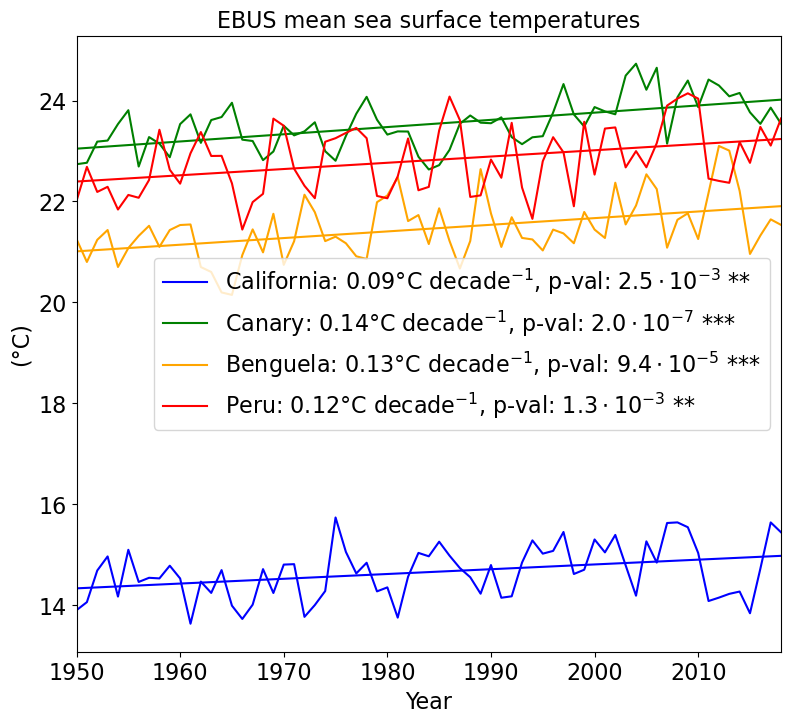

In [8]:
%%time
plt.figure(figsize=(20,8))
for f in [0,1,2,3]:#range(5):
    if f in [0,1,2,3]:
        ds = xr.open_mfdataset('/gxfs_work/geomar/smomw723/EddiesHC_analysis/EBUS_project/'+'output_'+maske[f][:3]+'_grid_T.nc').sosstsst.mean(['lat', 'lon'])
        ds = ds.groupby('time_counter.year').mean('time_counter')
        plt.subplot(1,2,1)
    if f == 4: 
        ds = sst
        plt.subplot(1,2,2)
    # calculating linear trend in the time series
    result = linregress(time, ds)
    # print("slope:", result.slope); print("p-value:", result.pvalue); print("R²:", result.rvalue**2)
    mantissa, exponent = f"{result.pvalue:.1e}".split("e") # round to 1 digit & convert for better writing in latex-style, i.e., 6.5 * 10^{-274}

    # some fancy stars to add significance level :D
    if result.pvalue  < 0.001: stars = '***' # highly significant
    elif result.pvalue  < 0.01: stars = '**'   # very significant
    elif result.pvalue  < 0.05: stars = '*'    # significant
    elif result.pvalue  >= 0.05: stars = ' '   # not significant

    z = np.polyfit(time, ds, 1); poly1 = np.poly1d(z) # create polynomial

    plt.plot(ds.year, ds, color=colours[f])                                    # ↓ multiply trend by 10 to get decadal trend
    plt.plot(time, poly1(time), label=maske_title[f]+': '+ str(np.round(poly1[1]*10 ,2)) + r'°C decade$^{-1}$, p-val: ' + rf"${mantissa} \cdot 10^{{{int(exponent)}}}$" + ' '+ stars, color=colours[f])

    plt.legend(fontsize=16)#loc="upper left", bbox_to_anchor=(1.02, 1))

    if f != 4: 
        plt.ylabel('(°C)', fontsize=16)
        plt.title('EBUS mean sea surface temperatures', y=1, fontsize=16)
    if f == 4: 
        plt.ylabel(None)
        plt.title('GLobal mean sea surface temperatures', y=1, fontsize=16)
    plt.xlabel('Year', fontsize=16)
    plt.xticks(fontsize=16); plt.yticks(fontsize=16)
    plt.xlim([1950,2018]) # set y axis limit

# --- saving as 300 dpi .PNG image in specified folder --------------------- #
plt.savefig(save + 'MLT_budget_EBUS_region_SSTs',
            dpi=300, facecolor='w',                                          #
            edgecolor='w', orientation='landscape',                          #
            format=None, transparent=False, bbox_inches='tight',             #
            pad_inches=0.1, metadata=None)                                   #
# --- end of script -------------------------------------------------------- # 
# Wall time: 11.6 s

In [ ]:
        if year == 1950: # at the start of the data, I miss one time step because of the differentiation
            nan_step = xr.full_like(dHdt_lhs.isel(time_counter=0), np.nan).expand_dims(time_counter=[sum_rhs.time_counter.values[0]])
            dHdt_lhs = xr.concat([nan_step, dHdt_lhs], dim="time_counter")

        # making all time-related coordinates identical to sum_rhs
        dHdt_lhs = dHdt_lhs.assign_coords(time_counter=sum_rhs.time_counter, time_instant=sum_rhs.time_instant, time_centered=sum_rhs.time_centered)
        dHdt_lhs = dHdt_lhs * area_t

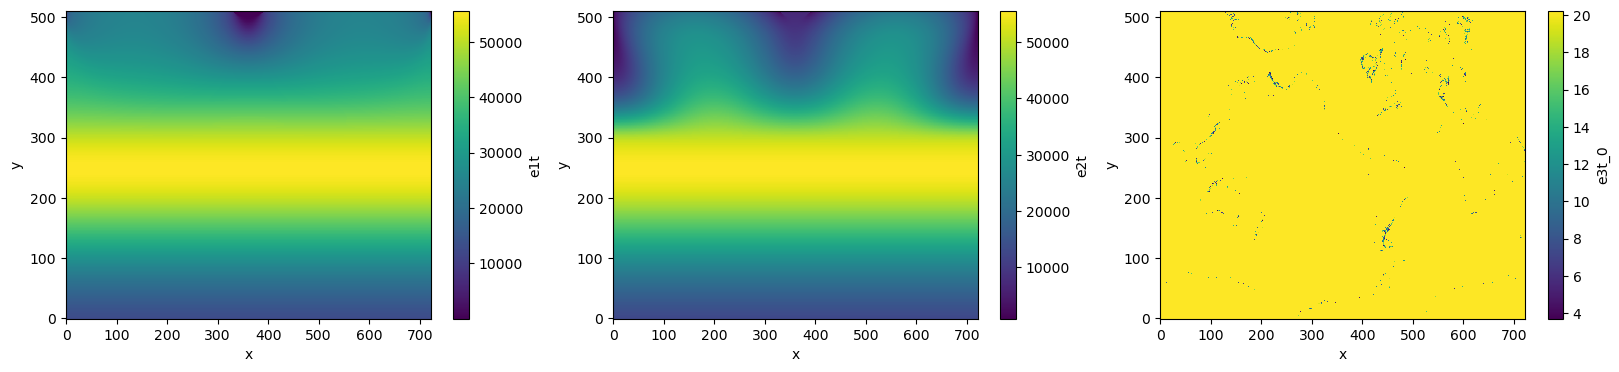

In [5]:
vars = ['votemper']
fn   = ['_grid_T']
freq = ['_1m_', '_1y_']

# ocean grid cell area [m2]
mesh_mask = xr.open_mfdataset('/gxfs_home/geomar/smomw723/EddiesHC_data/mesh_mask.nc')
# create empty 180x360 mesh grid where I put in data from e1t, e2t, e3t
plt.figure(figsize=(20,4)); plt.subplot(1,3,1); mesh_mask.e1t.plot(); plt.subplot(1,3,2); mesh_mask.e2t.plot(); plt.subplot(1,3,3); mesh_mask.e3t_0.squeeze()[10,:,:].plot()

In [72]:
mesh_mask.e1t

<xarray.DataArray 'e1t' (t: 1, y: 511, x: 722)> Size: 3MB
dask.array<open_dataset-e1t, shape=(1, 511, 722), dtype=float64, chunksize=(1, 64, 46), chunktype=numpy.ndarray>
Dimensions without coordinates: t, y, x

In [50]:
area_t

<xarray.DataArray (y: 511, x: 722)> Size: 3MB
dask.array<getitem, shape=(511, 722), dtype=float64, chunksize=(64, 46), chunktype=numpy.ndarray>
Dimensions without coordinates: y, x

In [ ]:
for s in [0,1,2]:#range(3): # loop through different data sets to prepare (i.e., time series, depth-integrated OHC & full OHC in each grid cell)
#    # if file already exists, skip this iteration of the loop
#    if os.path.exists(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+freq[t]+'OHC_MLD_'+str(year)+'.nc'):
#        print(str(year) + ' ' + dataset[s] + ' OHC already done')
#        continue
#    else:
#        print(str(year) + ' ' + dataset[s] + ' OHC creating now')

        # open main datasets here
        if freq[t] == '_1m_': # for monthly data, the output is in the main folder
            grid_OHC = archive2+exp_names[f]+'/outdata/nemo/'+exp_names[f]+freq[t]+str(year)+'0101_'+str(year)+'1231_grid_OHC.nc'
            grid_T   = archive2+exp_names[f]+'/outdata/nemo/'+exp_names[f]+freq[t]+str(year)+'0101_'+str(year)+'1231_grid_T.nc'
            scalar   = archive2+exp_names[f]+'/outdata/nemo/'+exp_names[f]+freq[t]+str(year)+'0101_'+str(year)+'1231_scalar.nc'
        if freq[t] == '_1y_': # for yearly data, I need to get into one more subfolder
            grid_OHC = archive2+exp_names[f]+'/outdata/nemo/ym/'+exp_names[f]+freq[t]+str(year)+'0101_'+str(year)+'1231_grid_OHC.nc'
            grid_T   = archive2+exp_names[f]+'/outdata/nemo/ym/'+exp_names[f]+freq[t]+str(year)+'0101_'+str(year)+'1231_grid_T.nc'

        # open data sets
        ds_OHC = xr.open_mfdataset(grid_OHC, decode_times=True, use_cftime=False, chunks={"time_counter": 1}) # heat content data sets with all variables as °C/s
        deptht = xr.open_dataset(grid_T, decode_times=True, use_cftime=False, chunks={"time_counter": 1}).e3t # ocean depth data
        somxl010 = xr.open_dataset(grid_T, decode_times=True, use_cftime=False, chunks={"time_counter": 1}).somxl010 # ocean depth data

        #  (time_counter: 12, deptht: 46, y: 511, x: 722)
        # additional calculations here to only select data above the mixed layer depth
        sum_rhs     = (ds_OHC[vars_to_sum].to_array().sum("variable") * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # [J m-2]

        OHC_xad    = (ds_OHC.ttrd_xad * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # zonal advection of ocean heat content [J m-2]
        OHC_yad    = (ds_OHC.ttrd_yad * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # meridional advection [J m-2]
        OHC_zad    = (ds_OHC.ttrd_zad * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # vertical advection [J m-2]
        
        OHC_ldf    = (ds_OHC.ttrd_ldf * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # lateral diffusion [J m-2]
        OHC_zdf    = (ds_OHC.ttrd_zdf * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # vertical diffusion [J m-2]

        OHC_qns    = (ds_OHC.ttrd_qns * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # non-solar radiative flux [J m-2]
        OHC_qsr    = (ds_OHC.ttrd_qsr * rho_0 * C_p * area_t * deptht * (60*60*24*30.5)).where(ds_OHC.deptht <= somxl010) # solar radiative flux [J m-2]

        # for the left-hand side, I need to open two datasets and then take the time-derivative, otherwise I cannot take the 
        # time-derivative of the last data entry each year
        a = []; b = [] # empty lists which I fill up continuously
        for i in range(2): # loop through the number of files I would like
            # for differentiations, I need the data for year_X-1 + year_X + 
            # fill in empty list with integers trailing two zeros (000, 001, 002, ...)
            if year==1950 and i == 0: year2 = year
            if year==1950 and i == 1: year2 = year+1
            if year!=1950 and i == 0: year2 = year-1
            if year!=1950 and i == 1: year2 = year2+1
            a.append(i); a[i] = archive2+exp_names[7]+'/outdata/nemo/'+exp_names[7]+'_1m_'+str(year2)+'0101_'+str(year2)+'1231_grid_OHC.nc' # string with all file locations
            b.append(i); b[i] = archive2+exp_names[7]+'/outdata/nemo/'+exp_names[7]+'_1m_'+str(year2)+'0101_'+str(year2)+'1231_grid_T.nc'

        # here also only select the North Atlantic mask data
        ds_OHC_extended   = xr.open_mfdataset(a, decode_times=True, use_cftime=False, combine='by_coords', chunks={"time_counter": 1}).where(mask_NAO)
        deptht_extended   = xr.open_mfdataset(b, decode_times=True, use_cftime=False, combine='by_coords', chunks={"time_counter": 1}).e3t.where(mask_NAO)
        somxl010_extended = xr.open_mfdataset(a, decode_times=True, use_cftime=False, combine='by_coords', chunks={"time_counter": 1}).somxl010inst.where(mask_NAO)

        # [J m-2]
#                    dHdt_lhs = (ds_OHC_extended.where(ds_OHC_extended.deptht <= somxl010_extended).tempinst.diff('time_counter').sel(time_counter=str(year)) * deptht_extended * rho_0 * C_p)
        dHdt_lhs = (ds_OHC_extended.where(ds_OHC_extended.deptht <= somxl010_extended).tempinst.diff('time_counter').sel(time_counter=str(year)) * deptht_extended * rho_0 * C_p)

        if year == 1950: # at the start of the data, I miss one time step because of the differentiation
            nan_step = xr.full_like(dHdt_lhs.isel(time_counter=0), np.nan).expand_dims(time_counter=[sum_rhs.time_counter.values[0]])
            dHdt_lhs = xr.concat([nan_step, dHdt_lhs], dim="time_counter")

        # making all time-related coordinates identical to sum_rhs
        dHdt_lhs = dHdt_lhs.assign_coords(time_counter=sum_rhs.time_counter, time_instant=sum_rhs.time_instant, time_centered=sum_rhs.time_centered)
        dHdt_lhs = dHdt_lhs * area_t

        # load the data, assign variables and save into a netcdf file
        if dataset[s] == 'time_series':
            OHC_manual = xr.Dataset({'dHdt_lhs': dHdt_lhs.sum(['deptht', 'y', 'x']),
                                     'sum_rhs':  sum_rhs.sum(['deptht', 'y', 'x']),
                                     'OHC_xad':  OHC_xad.sum(['deptht', 'y', 'x']),
                                     'OHC_yad':  OHC_yad.sum(['deptht', 'y', 'x']),
                                     'OHC_zad':  OHC_zad.sum(['deptht', 'y', 'x']),
        
                                     'OHC_ldf':  OHC_ldf.sum(['deptht', 'y', 'x']),
                                     'OHC_zdf':  OHC_zdf.sum(['deptht', 'y', 'x']),
        
                                     'OHC_qns':  OHC_qns.sum(['deptht', 'y', 'x']),
                                     'OHC_qsr':  OHC_qsr.sum(['deptht', 'y', 'x']),
                                     'OHC_res':  (dHdt_lhs - sum_rhs).sum(['deptht', 'y', 'x'])})
        if dataset[s] == 'depth_integrated':
            OHC_manual = xr.Dataset({'dHdt_lhs': dHdt_lhs.sum(['deptht']),
                                     'sum_rhs':  sum_rhs.sum(['deptht']),
                                     'OHC_xad':  OHC_xad.sum(['deptht']),
                                     'OHC_yad':  OHC_yad.sum(['deptht']),
                                     'OHC_zad':  OHC_zad.sum(['deptht']),
        
                                     'OHC_ldf':  OHC_ldf.sum(['deptht']),
                                     'OHC_zdf':  OHC_zdf.sum(['deptht']),
        
                                     'OHC_qns':  OHC_qns.sum(['deptht']),
                                     'OHC_qsr':  OHC_qsr.sum(['deptht']),
                                     'OHC_res':  (dHdt_lhs - sum_rhs).sum(['deptht'])})
        if dataset[s] == 'full':
            OHC_manual = xr.Dataset({'dHdt_lhs': dHdt_lhs,
                                     'sum_rhs':  sum_rhs,
                                     'OHC_xad':  OHC_xad,
                                     'OHC_yad':  OHC_yad,
                                     'OHC_zad':  OHC_zad,
        
                                     'OHC_ldf':  OHC_ldf,
                                     'OHC_zdf':  OHC_zdf,
        
                                     'OHC_qns':  OHC_qns,
                                     'OHC_qsr':  OHC_qsr,
                                     'OHC_res':  (dHdt_lhs - sum_rhs)})
        # add attributes for good metadata
        OHC_manual.attrs = {
            'Author': 'Maurice F. Huguenin', 
            'Affiliation': 'GEOMAR Helmholtz Centre for Ocean Research Kiel',
            'Project': 'DFG project CHOICE: Ocean heat and carbon storage under ambitious emission mitigation',
            'Data set': exp_names[f] + ' global ' + dataset[s] + ' ocean heat content with ' + freq[t] + ' frequency',
            'Unit': '[J m-2]',
            'Created': datetime.today().strftime('%Y-%m-%d'),
            'Mail': 'mhuguenin-virchaux@geomar.de', 
            'Funding': 'DFG funding code 538865427'}
        OHC_manual.to_netcdf(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+freq[t]+'OHC_MLD_'+str(year)+'.nc', engine='netcdf4') 

        # close open datasets
        ds_OHC.close(); ds_OHC_extended.close(); deptht_extended.close() 
        
        # delete large objects
        del (ds_OHC, ds_OHC_extended, deptht, deptht_extended, sum_rhs, OHC_xad, OHC_yad, OHC_zad, OHC_ldf, OHC_zdf, OHC_qns,OHC_qsr, dHdt_lhs, OHC_manual)

        # release unreachable memory
        import gc; gc.collect()
# Wall time: 28min 15s for time series for one year
# Wall time: 23min 17s for depth_integrated for one year

In [ ]:
%%time
vars = ['dHdt_lhs', 'sum_rhs', 
        'OHC_xad', 'OHC_yad', 'OHC_zad',
        'OHC_ldf', 'OHC_zdf',
        'OHC_qns', 'OHC_qsr', 
        'OHC_res']
var_title = ['Change in heat content', 'Sum of panels b-i',
             'Zonal advection','Meridional advection','Vertical advection',
             'Horizontal diffusion','Vertical diffusion',
             'Non-solar heat flux + runoff',
             'Solar heat flux',
             'Residual']

ds = xr.open_mfdataset('/gxfs_work/geomar/smomw723/EddiesHC_analysis/FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets/'+'FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets_time_series_1m_OHC_MLD_1980.nc')
plt.figure(figsize=(6,6))
for f in range(10):
    ds[vars[f]].plot(label=var_title[f]);
    if f == 9: plt.text(ds[vars[f]].time_counter[1], -1e23, 'OHC_res $\mu$: '+f"{np.round(ds[vars[f]].mean().values,2):.2e}")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
# --- saving as 300 dpi .PNG image in specified folder --------------------- #
plt.savefig(save + 'Heat_budget_closure_time_series_including_residual_from_Jul1980_test_case_MH009',
            dpi=300, facecolor='w',                                          #
            edgecolor='w', orientation='landscape',                          #
            format=None, transparent=False, bbox_inches='tight',             #
            pad_inches=0.1, metadata=None)                                   #
# --- end of script -------------------------------------------------------- # 
# Wall time: 6min 54s

### Open data and functions for plotting

In [ ]:
%%time
ds = xr.open_mfdataset('/gxfs_work/geomar/smomw723/EddiesHC_analysis/FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets/'+'FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets_depth_integrated_1m_OHC_MLD_1980.nc')

# detect coordinate names
lat_name = [c for c in ds.coords if "lat" in c.lower()][0]
lon_name = [c for c in ds.coords if "lon" in c.lower()][0]

lat = ds[lat_name].values
lon = ds[lon_name].values

# 2D mesh or already lat2D/lon2D
if lat.ndim == 1 and lon.ndim == 1:
    lon2d, lat2d = np.meshgrid(lon, lat)
else:
    lon2d, lat2d = lon, lat

z = np.squeeze(ds.values)   # ensure 2-D

# convert lon to -180..180 for Cartopy
if np.nanmax(lon2d) > 180:
    lon2d = ((lon2d + 180) % 360) - 180
    
ticks = np.linspace(0,3,21) # ticks for colour bar

def fancy_plot(axes_nr):
    axes_nr.coastlines(resolution = '50m') # add coast lines
    axes_nr.add_feature(cfeature.LAND, edgecolor = 'black', facecolor = [.83, .83, .83], zorder = 1)


In [ ]:
%%time
vars = ['dHdt_lhs', 
        'OHC_xad', 'OHC_yad', 'OHC_zad',
        'OHC_ldf', 'OHC_zdf',
        'OHC_qns', 'OHC_qsr', 
        'OHC_res']
var_title = ['Change in heat content',
             'Zonal advection','Meridional advection','Vertical advection',
             'Horizontal diffusion','Vertical diffusion',
             'Non-solar heat flux + runoff',
             'Solar heat flux',
             'Residual']


#var_titles = ['Specific humidity', 'Sea level pressure', 'Surface air temperature', 'Zonal wind speed', 'Meridional wind speed',
#             'Rainfall', 'Snowfall', 'Downward longwave', 'Downward shortwave', 'River runoff']

#var_units = ['10$^{-2}$ kg kg$^{-1}$', 'hPa', '°C', 'm s$^{-1}$', 'm s$^{-1}$',
#             '10$^{-5}$ kg m$^{-2}$ s$^{-1}$', '10$^{-6}$ kg m$^{-2}$ s$^{-1}$', 'W m$^{-2}$', 'W m$^{-2}$', 'kg m$^{-2}$ s$^{-1}$']
var_units = 'J m$^{-2}$'
level_steps = [-1,1]

for f in range(1): # loop through El Nino and La Nina
    # initialise figure     ( l, h) -> length and height of plot 
    fig = plt.figure(figsize=(16,9),tight_layout=True,facecolor='w',edgecolor='k') 

    for v in range(9): # loop through all variables
        
        field = ds[vars[v]][6,:,:]
        

        exponent_scaling = 1e19
        
        #s = [2,3,4,0,0,5,6,0,0,0,0,7,8,0,1,9]
        ax1 = plt.subplot(4,3,v+1, projection=ccrs.Robinson(central_longitude=200)) # longitude starting at Cape Agulhas (20°E)
        plt.title(var_title[v], fontsize=16)
        ax1.text(-.1, .9,string.ascii_lowercase[v], transform=ax1.transAxes, size=16, weight='bold') # bold letter a at the top

        # ------------------------------------ #
        p1  = ax1.pcolormesh(lon, lat, field/exponent_scaling, vmin=level_steps[0], vmax=level_steps[1], transform=ccrs.PlateCarree(), cmap='RdBu_r')
        #p11 = ax1.contour(lon, lat, field, levels=[1], linewidths=.1, colors='lightgrey', transform=ccrs.PlateCarree())
        # ------------------------------------ #
# Wall time: 1min 44s

        # add colour bar   
        cb = plt.colorbar(p1, shrink=.75, orientation='vertical'); 
        unit_label = '(10$^{9}$ '
        cb.set_label(label=unit_label+var_units+')', size=16)
        cb.ax.tick_params(labelsize=16); tick_locator = ticker.MaxNLocator(nbins=4)
        cb.ax.yaxis.get_offset_text().set_fontsize(16) # set size of exponent if it appears
        cb.locator = tick_locator;cb.update_ticks() 
#        cb.add_lines(p11) # add contours to colour bar
        
        fancy_plot(ax1)

        if v < 6: ax1.set_xticklabels([])  # remove unnecessary tick labels
        if v in [1,2,4,5,7,8]: ax1.set_yticklabels([])

        # add annotation text into middle of maps
#        ax1.text(0, 0, unit_vars, ha='center', va='center', fontsize=16).set_path_effects([PathEffects.withStroke(linewidth=3, foreground='w')])
    
    plt.suptitle('MH009 Jul. 1980 heat budget closure', fontsize=16, fontweight='bold', y=.99)

    # --- saving as 300 dpi .PNG image in specified folder --------------------- #
    plt.savefig(save + 'Heat_budget_closure_including_residual_from_Jul1980_test_case_MH009',
                dpi=300, facecolor='w',                                          #
                edgecolor='w', orientation='landscape',                          #
                format=None, transparent=False, bbox_inches='tight',             #
                pad_inches=0.1, metadata=None)                                   #
    # --- end of script -------------------------------------------------------- # 
# Wall time: 1min 41s

In [ ]:
#xr.open_mfdataset(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+freq[t]+'OHC_'+str(year)+'.nc').dHdt_lhs.plot()
#xr.open_mfdataset(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+freq[t]+'OHC_'+str(year)+'.nc').sum_rhs.plot()

ds = xr.open_mfdataset(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+freq[t]+'OHC_*.nc')

dHdt_lhs = ds.dHdt_lhs; sum_rhs = ds.sum_rhs

OHC_xad = ds.OHC_xad; OHC_yad = ds.OHC_yad; OHC_zad = ds.OHC_zad
OHC_ldf = ds.OHC_ldf; OHC_zdf = ds.OHC_zdf
OHC_qns = ds.OHC_qns; OHC_qsr = ds.OHC_qsr

plt.figure(figsize=(8,8))
#plt.plot((OHC_xad+OHC_yad+OHC_zad+OHC_ldf+OHC_zdf+OHC_qns+OHC_qsr), label='manual_sum_rhs'); plt.legend()

plt.plot(OHC_xad, label='OHC_xad')
plt.plot(OHC_yad, label='OHC_yad')
plt.plot(OHC_zad, label='OHC_zad')

plt.plot(OHC_ldf, label='OHC_ldf')
plt.plot(OHC_zdf, label='OHC_zdf')

plt.plot(OHC_qns, label='OHC_qns')
plt.plot(OHC_qsr, label='OHC_qsr') 

plt.plot(dHdt_lhs, label='dHdt_lhs', lw=2, linestyle='-')
plt.plot(sum_rhs, label='sum_rhs', lw=2, linestyle='-')

plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

In [ ]:
%%time
plt.figure(figsize=(16,4)); ticks = np.linspace(-1e10,1e10,10)
a = DS4.dHdt_lhs[1,:,:,:].sum('deptht')
b = DS4.sum_rhs[1,:,:,:].sum('deptht')
plt.subplot(1,3,1); a.plot(levels=ticks);     plt.title('dHdt_lhs')
plt.subplot(1,3,2); b.plot(levels=ticks);     plt.title('sum_rhs')
plt.subplot(1,3,3); (a-b).plot(levels=ticks); plt.title('a-b')
# Wall time: 12 s Perfect, all good

In [ ]:
DS4 = xr.Dataset({'huss_10m': ts_huss_10m, 'psl': ts_psl, 'tas_10m': ts_tas_10m,
                      'uas_10m': ts_uas_10m, 'vas_10m': ts_vas_10m,
                      'prrn': ts_prrn, 'prsn': ts_prsn,
                      'rlds': ts_rlds, 'rsds': ts_rsds})
    DS4.to_netcdf('/g/data/e14/mv7494/IPOAnt_input/time_series/ts_'+suffix+'.nc')  

In [ ]:
ds_OHC.ttrd_xad

In [ ]:
a = ds_OHC_extended.tempinst.diff('time_counter')[0,0,:,:]
b = (ds_OHC_extended.tempinst[1,:,:,:]-ds_OHC_extended.tempinst[0,:,:,:])[0,:,:]
plt.figure(figsize=(16,4))
plt.subplot(1,3,1); a.plot()
plt.subplot(1,3,2); b.plot()
plt.subplot(1,3,3); (a-b).plot()

In [ ]:

((ds_OHC_extended.tempinst[1,:,:,:]-ds_OHC_extended.tempinst[1-1,:,:,:]) * deptht[1-1,:,:,:] * rho_0 * C_p).sum('deptht').plot()

In [ ]:
for f in range(1,12,1):
    print(f)
    dHdt_lhs   = ((ds_OHC_extended.tempinst[f,:,:,:]-ds_OHC_extended.tempinst[f-1,:,:,:]) * deptht[f-1,:,:,:] * rho_0 * C_p)

In [ ]:
ds_OHC_extended = xr.open_mfdataset(archive2+exp_names[7]+'/outdata/nemo/'+exp_names[7]+'_1m_'+files[0]+'_grid_OHC.nc', 
                                    decode_times=True, use_cftime=False, combine='by_coords')
#    dHdt_lhs[f,:,:,:]   = ((ds_OHC.tempinst[f,:,:,:]-ds_OHC.tempinst[f-1,:,:,:]) * deptht[0,:,:,:] * rho_0 * C_p)
# ---------------------------------------------------------------------------------------------------------------------- #
# Wall time. 14.9 s per month

In [ ]:
archive2+exp_names[7]+'/outdata/nemo/'+exp_names[7]+'_1m_20100101_20101231_grid_OHC.nc'

In [ ]:
(sum_rhs[1,:,:,:]/1e8).mean('deptht').plot(levels=np.linspace(-1,1,10))

In [ ]:
ttrd_xad

In [ ]:
plt.figure(figsize=(16,4)); ticks = np.linspace(-1,1,10)
plt.subplot(1,3,1); (sum_rhs/1e10).plot(levels=ticks)
plt.subplot(1,3,2); (dHdt_lhs/1e10).plot(levels=ticks)
residual = dHdt_lhs - sum_rhs
plt.subplot(1,3,3); (residual/1e10).plot(levels=ticks)

In [ ]:
for f in [8]: # loop through the experiments, that is PI-CTRL and the scenario simulation
    if f in [7, 8]: archive_link = archive2
    else:           archive_link = archive
    print(exp_labels[f])
    if f in [0,1]: date_range = range(1980,2019,1) # historical period for hist
    if f in [2,3]: date_range = range(2070,2100,1) # future end of century period for RESCUE

    # new RESCUE simulations
    if f in [4]: date_range = range(1950,2100,1) # PI-CTRL date range
    if f in [5]: date_range = range(1950,2014,1) # cmip6hist date range
    if f in [6]: date_range = range(2014,2100,1) # ssp119 1.5°C high overshoot scenario date range

    # new historical simulation from 1980-2018 with CC105 'CONSERV' interpolation technique
    if f in [7]: date_range = range(1950,1951,1) 
    if f in [8]: date_range = range(1950,1951,1) # same for the parallel-running PI-CTRL
        
    for year in date_range: # loop through every year of the data set
        for s in range(3): # loop through the different data sets to prepare (e.g., time series, depth-integrated OHC & full OHC in every
                   # grid cell
            # if file already exists, skip this iteration of the loop
            if os.path.exists(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+'_OHC_'+str(year)+'.nc'):
                if year == date_range[-1]: print('all '+dataset[s]+' OHC budget files already done')
                continue
            else:
                print(str(year) + ' ' + dataset[s] + ' OHC budget creating now')
            if year%10== 0: print('---------------------------------------------')

            if dataset[s] == 'time_series':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='OHC_manual')
                sum_rhs    = (ds_OHC[vars_to_sum].to_array().sum("variable")* rho_0 * C_p * deptht * (60*60*24*28))[1,:,:,:].sum('deptht')
                dHdt_lhs   = ((ds_OHC.tempinst[f,:,:,:]-ds_OHC.tempinst[f-1,:,:,:]) * deptht[f-1,:,:,:] * rho_0 * C_p).sum(['deptht']) # 33 days between 1 Feb and 31 Dec 2015

                ttrd_xad   = (rho_0 * C_p * ttrd_xad * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_xad')

            for f in range(12): # loop through the time dimension of the dataset
                for v in range(16): # loop through all variables
            
                    # for each variable, create an OHC array that will progressively get filled up
                    
                    # only plot the OHC budget terms for the first month and the surface layer, i.e., [0,0,:,:]
                    if v in [0,1,2,3,5,6,7,8,9,10,11,12,13]: field[f,:,:] = (vars[v] * rho_0 * C_p * deptht * (60*60*24*28))[f,:,:,:].sum(['deptht'])
                    if v in [4]: field[f,:,:] = vars[v][f,:,:] # the ttrd_sad field is only 3D
                    if v == 14: 
                        vars_to_sum = ['ttrd_xad', 'ttrd_yad', 'ttrd_zad', 'ttrd_ldf', 'ttrd_zdf', 'ttrd_qns', 'ttrd_qsr']
                        vars_to_sum = ['ttrd_xad', 'ttrd_yad', 'ttrd_zad', 'ttrd_ldf', 'ttrd_zdf', 'ttrd_qns', 'ttrd_qsr']
                        sum_rhs = (ds_OHC[vars_to_sum].to_array().sum("variable")* rho_0 * C_p * deptht * (60*60*24*28))[1,:,:,:].sum('deptht')
                        field[f,:,:]       = sum_rhs
                    if v == 15: 
                        dHdt_lhs = ((ds_OHC.tempinst[f,:,:,:]-ds_OHC.tempinst[f-1,:,:,:]) * deptht[f-1,:,:,:] * rho_0 * C_p).sum(['deptht']) # 33 days between 1 Feb and 31 Dec 2015
                        field[f,:,:] = dHdt_lhs - sum_rhs




            
            votemper = xr.open_mfdataset(archive_link + exp_names[f] + '/outdata/nemo/' + exp_names[f] + freq[0] + str(year)+'*_grid_T.nc', chunks={'time': '200MB'}).votemper # grid cell pot. temp.
            e3t      = xr.open_mfdataset(archive_link + exp_names[f] + '/outdata/nemo/' + exp_names[f] + freq[0] + str(year)+'*_grid_T.nc', chunks={'time': '200MB'}).e3t.squeeze() # grid cell depth

            if dataset[s] == 'time_series':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='OHC_manual').load()
                sum_rhs    = (ds_OHC[vars_to_sum].to_array().sum("variable")* rho_0 * C_p * deptht * (60*60*24*28))[1,:,:,:].sum('deptht')
                dHdt_lhs   = ((ds_OHC.tempinst[f,:,:,:]-ds_OHC.tempinst[f-1,:,:,:]) * deptht[f-1,:,:,:] * rho_0 * C_p).sum(['deptht']) # 33 days between 1 Feb and 31 Dec 2015

                ttrd_xad   = (rho_0 * C_p * ttrd_xad * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_xad').load()
                ttrd_yad   = (rho_0 * C_p * ttrd_yad * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_yad').load()
                ttrd_zad   = (rho_0 * C_p * ttrd_zad * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_zad').load()

                ttrd_ldf   = (rho_0 * C_p * ttrd_ldf * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_ldf').load()
                ttrd_xad   = (rho_0 * C_p * ttrd_xad * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_xad').load()


                ttrd_qns   = (rho_0 * C_p * ttrd_qns * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_qns').load()
                ttrd_qsr   = (rho_0 * C_p * ttrd_qsr * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='ttrd_qsr').load()

            
            if dataset[s] == 'depth_integrated':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).sum(['deptht']).to_dataset(name='OHC_manual').load()
            if dataset[s] == 'full':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).to_dataset(name='OHC_manual').load()
    
            OHC_manual.attrs = {
                'Author': 'Maurice F. Huguenin', 
                'Affiliation': 'GEOMAR Helmholtz Centre for Ocean Research Kiel',
                'Project': 'DFG project CHOICE: Ocean heat and carbon storage under ambitious emission mitigation',
                'Data set': exp_names[f] + ' global ' + dataset[s] + ' ocean heat content ',
                'Unit': '[J]',
                'Created': datetime.today().strftime('%Y-%m-%d'),
                'Mail': 'mhuguenin-virchaux@geomar.de', 
                'Funding': 'DFG funding code 538865427'}
            OHC_manual.compute().to_netcdf(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+'_OHC_'+str(year)+'.nc', engine='scipy') 
    print('---------------------------------------------------')
# 15 min per year (for both PI-CTRL & hist

In [ ]:
%%time
#plt.figure(figsize=(12,4))
archive   = '/gxfs_work/geomar/smomw723/'
archive2  = '/gxfs_work/geomar/smomw447/models/esm-experiments/'

exp_names = ['FOCI2.0_MH002_PI-CTRL_ESM_1979CC103_incl-OHC-DIC-budgets', 
             'FOCI2.00.0-MH001_hist_ESM_incl_OHC_DIC', 
             'FOCI2.0_MH004_RESCUE-PI-CTRL_ESM_2069SB019_incl-OHC-DIC-budgets', 
             'FOCI2.0_MH003_RESCUE_ESM_2069SB011_incl-OHC-DIC-budgets',

             'FOCI2.0_MH007_RESCUE-PI-CTRL_ESM_1949SB019_incl-OHC-DIC-budgets',
             'FOCI2.0_MH006_RESCUE-cmip6hist_ESM_1949SB008_incl-OHC-DIC-budgets',
             'FOCI2.0_MH008_RESCUE-1dot5hOS_ESM_2014MH006_incl-OHC-DIC-budgets',
            
             'FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets',
             'FOCI2.0_MH010_PI-CTRL_ESM_1949CC103_incl-OHC-DIC-budgets']

exp_labels = ['FOCI2.0_MH002_PI-CTRL', 'FOCI2.0-MH001_hist', 'FOCI2.0_MH004_RESCUE-PI-CTRL', 'FOCI2.0_MH003_RESCUE',
             'FOCI2.0_MH007_RESCUE-PI-CTRL', 'FOCI2.0_MH006_RESCUE-cmip6hist','FOCI2.0_MH008_RESCUE-1dot5hOS',
             'FOCI2.0_MH009_cmip6hist', 'FOCI2.0_MH010_PI-CTRL']

vars = ['votemper']
fn   = ['_grid_T']
freq = ['_1m_', '_1y_']

# ocean grid cell area [m2]
area_t = xr.open_mfdataset('/gxfs_home/geomar/smomw723/EddiesHC_data/mesh_mask.nc')
area_t = (area_t.e1t*area_t.e2t).squeeze()
#area_t.plot(); plt.title('NEMO grid cell area (m$^{2}$)')

# ocean grid cell depth [m]
ht = xr.open_mfdataset('/gxfs_home/geomar/smomw723/EddiesHC_data/bathy_meter__4.2.0_ORCA05.L46.nc').Bathymetry

rho_0 = 1025.022            # global ocean reference density of sea water used in FOCI-MOPS [kg m^{-3}]
C_p   = 3992.10322329649    # global ocean average specific heat capacity [J kg^{-1} K^{-1}]

dataset = ['time_series', 'depth_integrated', 'full']

for f in [7,8]: # loop through the experiments, that is PI-CTRL and the scenario simulation
    if f in [7, 8]: archive_link = archive2
    else:           archive_link = archive
    print(exp_labels[f])
    if f in [0,1]: date_range = range(1980,2019,1) # historical period for hist
    if f in [2,3]: date_range = range(2070,2100,1) # future end of century period for RESCUE

    if f in [4]: date_range = range(1950,2100,1) # new RESCUE simulation PI-CTRL date range
    if f in [5]: date_range = range(1950,2014,1) # new RESCUE simulation cmip6hist date range
    if f in [6]: date_range = range(2014,2100,1) # new RESCUE simulation ssp119 1.5°C high overshoot scenario date range

    # new historical simulation from 1980-2018 with CC105 'CONSERV' interpolation technique
    if f in [7]: date_range = range(1950,2019,1) 
    if f in [8]: date_range = range(1950,2019,1) # same for the parallel-running PI-CTRL
        
    for year in date_range: # loop through every year of the data set
        for s in range(3): # loop through the different data sets to prepare (e.g., time series, depth-integrated OHC & full OHC in every
                   # grid cell
            # if file already exists, skip this iteration of the loop
            if os.path.exists(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+'_OHC_'+str(year)+'.nc'):
                if year == date_range[-1]: print('all '+dataset[s]+' OHC files already done') # print(str(year) + ' ' + dataset[s] + ' OHC already done')
                continue
            else:
                print(str(year) + ' ' + dataset[s] + ' OHC creating now')

            votemper = xr.open_mfdataset(archive_link + exp_names[f] + '/outdata/nemo/' + exp_names[f] + freq[0] + str(year)+'*_grid_T.nc', chunks={'time': '200MB'}).votemper # grid cell pot. temp.
            e3t      = xr.open_mfdataset(archive_link + exp_names[f] + '/outdata/nemo/' + exp_names[f] + freq[0] + str(year)+'*_grid_T.nc', chunks={'time': '200MB'}).e3t.squeeze() # grid cell depth

            if dataset[s] == 'time_series':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).sum(['deptht', 'y', 'x']).to_dataset(name='OHC_manual').load()
            if dataset[s] == 'depth_integrated':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).sum(['deptht']).to_dataset(name='OHC_manual').load()
            if dataset[s] == 'full':
                OHC_manual = (rho_0 * C_p * votemper * area_t * e3t).to_dataset(name='OHC_manual').load()
    
            OHC_manual.attrs = {
                'Author': 'Maurice F. Huguenin', 
                'Affiliation': 'GEOMAR Helmholtz Centre for Ocean Research Kiel',
                'Project': 'DFG project CHOICE: Ocean heat and carbon storage under ambitious emission mitigation',
                'Data set': exp_names[f] + ' global ' + dataset[s] + ' ocean heat content ',
                'Unit': '[J]',
                'Created': datetime.today().strftime('%Y-%m-%d'),
                'Mail': 'mhuguenin-virchaux@geomar.de', 
                'Funding': 'DFG funding code 538865427'}
            OHC_manual.compute().to_netcdf(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+'_OHC_'+str(year)+'.nc', engine='scipy') 
    print('---------------------------------------------------')
# 15 min per year (for both PI-CTRL & hist

In [ ]:
archive_link + exp_names[f] + '/outdata/nemo/' + exp_names[f] + freq[0] + str(year)+'*_grid_T.nc'

# Postprocessing DIC fields

In [ ]:
%%time
#plt.figure(figsize=(12,4))
archive   = '/gxfs_work/geomar/smomw723/'
archive2  = '/gxfs_work/geomar/smomw447/models/esm-experiments/'

exp_names = ['FOCI2.0_MH002_PI-CTRL_ESM_1979CC103_incl-OHC-DIC-budgets', 
             'FOCI2.00.0-MH001_hist_ESM_incl_OHC_DIC', 
             'FOCI2.0_MH004_RESCUE-PI-CTRL_ESM_2069SB019_incl-OHC-DIC-budgets', 
             'FOCI2.0_MH003_RESCUE_ESM_2069SB011_incl-OHC-DIC-budgets',

             'FOCI2.0_MH007_RESCUE-PI-CTRL_ESM_1949SB019_incl-OHC-DIC-budgets',
             'FOCI2.0_MH006_RESCUE-cmip6hist_ESM_1949SB008_incl-OHC-DIC-budgets',
             'FOCI2.0_MH008_RESCUE-1dot5hOS_ESM_2014MH006_incl-OHC-DIC-budgets',
            
             'FOCI2.0_MH009_cmip6hist_ESM_1949CC105_incl-OHC-DIC-budgets',
             'FOCI2.0_MH010_PI-CTRL_ESM_1949CC103_incl-OHC-DIC-budgets']

exp_labels = ['FOCI2.0_MH002_PI-CTRL', 'FOCI2.0-MH001_hist', 'FOCI2.0_MH004_RESCUE-PI-CTRL', 'FOCI2.0_MH003_RESCUE',
             'FOCI2.0_MH007_RESCUE-PI-CTRL', 'FOCI2.0_MH006_RESCUE-cmip6hist','FOCI2.0_MH008_RESCUE-1dot5hOS',
             'FOCI2.0_MH009_cmip6hist', 'FOCI2.0_MH010_PI-CTRL']
vars = ['votemper']
fn   = ['_grid_T']
freq = ['_1m_', '_1y_']

# ocean grid cell area [m2]
area_t = xr.open_mfdataset('/gxfs_home/geomar/smomw723/EddiesHC_data/mesh_mask.nc')
area_t = (area_t.e1t*area_t.e2t).squeeze()
#area_t.plot(); plt.title('NEMO grid cell area (m$^{2}$)')

# ocean grid cell depth [m]
ht = xr.open_mfdataset('/gxfs_home/geomar/smomw723/EddiesHC_data/bathy_meter__4.2.0_ORCA05.L46.nc').Bathymetry

rho_0 = 1025.022            # global ocean reference density of sea water used in FOCI-MOPS [kg m^{-3}]
C_p   = 3992.10322329649    # global ocean average specific heat capacity [J kg^{-1} K^{-1}]

dataset = ['time_series', 'depth_integrated', 'full']

for f in [7]: # loop through the experiments, that is PI-CTRL and the scenario simulation
    if f in [7, 8]: archive_link = archive2
    else:           archive_link = archive
    print(exp_labels[f])
    if f in [0,1]: date_range = range(1980,2019,1) # historical period for hist
    if f in [2,3]: date_range = range(2070,2100,1) # future end of century period for RESCUE

    if f in [4]: date_range = range(1950,2100,1) # new RESCUE simulation PI-CTRL date range
    if f in [5]: date_range = range(1950,2014,1) # new RESCUE simulation cmip6hist date range
    if f in [6]: date_range = range(2014,2100,1) # new RESCUE simulation ssp119 1.5°C high overshoot scenario date range
        
    for year in date_range: # loop through every year of the data set
        for s in range(3): # loop through the different data sets to prepare (e.g., time series, depth-integrated OHC & full OHC in every
                   # grid cell
            # if file already exists, skip this iteration of the loop
            if os.path.exists(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+'_DIC_'+str(year)+'.nc'):
                if year == date_range[-1]: print('all '+dataset[s]+' DIC files already done')
                continue
            else:
                print(str(year) + ' ' + dataset[s] + ' DIC creating now')
                
            DIC = xr.open_mfdataset(archive_link + exp_names[f] + '/outdata/nemo/' + exp_names[f] + freq[0] + str(year)+'*_ptrc_T.nc', chunks={'time': '200MB'}).DIC # grid cell pot. temp.

            if dataset[s] == 'time_series':
                DIC_manual =                                     DIC.sum(['deptht', 'y', 'x']).to_dataset(name='DIC_manual').load()
            if dataset[s] == 'depth_integrated':
                DIC_manual =                                     DIC.sum(['deptht', ]).to_dataset(name='DIC_manual').load()
            if dataset[s] == 'full':
                DIC_manual =                                     DIC.to_dataset(name='DIC_manual').load()
            DIC_manual.attrs = {
                'Author': 'Maurice F. Huguenin', 
                'Affiliation': 'GEOMAR Helmholtz Centre for Ocean Research Kiel',
                'Project': 'DFG project CHOICE: Ocean heat and carbon storage under ambitious emission mitigation',
                'Data set': exp_names[f] + ' global ' + dataset[s] + ' dissolved inorganic carbon content ',
                'Unit': '[umol/kg]',
                'Created': datetime.today().strftime('%Y-%m-%d'),
                'Mail': 'mhuguenin-virchaux@geomar.de', 
                'Funding': 'DFG funding code 538865427'}
            DIC_manual.compute().to_netcdf(archive + 'EddiesHC_analysis/'+exp_names[f]+'/'+exp_names[f]+'_'+dataset[s]+'_DIC_'+str(year)+'.nc', engine='scipy') 
    print('---------------------------------------------------')
# Wall time: 1min 45s per year (for both PI-CTRL & hist

### Creating a basin_mask for FOCI-MOPS (with NEMO3.4)

In [ ]:
%%time
base = '/gxfs_work/geomar/smomw723/EddiesHC_analysis/'
basin_mask = xr.open_dataset(base + 'orca05_subbasins_3.6.nc')

basin = (basin_mask.atlmsk + basin_mask.pacmsk + basin_mask.indmsk) # full ocean
SO_mask = (basin.where(basin.Y < 175).fillna(0))
AO_mask = basin_mask.atlmsk.where(basin.Y > 176).where(basin.Y < 398).fillna(0)
PO_mask = basin_mask.pacmsk.where(basin.Y > 176).where(basin.Y < 419).fillna(0)
IO_mask = basin_mask.indmsk.where(basin.Y > 176).fillna(0)
Ar_mask = ((basin_mask.atlmsk).where(basin.Y > 398).fillna(0) + basin_mask.pacmsk.where(basin.Y > 419).fillna(0))

plt.figure(figsize=(20,8))
plt.subplot(2,3,1); basin.plot(cmap='Reds')
plt.subplot(2,3,2); SO_mask.plot(cmap='Reds'); plt.title('Southern Ocean south of 34°S')
plt.subplot(2,3,3); AO_mask.plot(cmap='Reds'); plt.title('Atlantic Ocean 34°S-60°N')
plt.subplot(2,3,4); PO_mask.plot(cmap='Reds'); plt.title('Pacific Ocean 34°S-65°N')
plt.subplot(2,3,5); IO_mask.plot(cmap='Reds'); plt.title('Indian Ocean north of 34°S')
plt.subplot(2,3,6); Ar_mask.plot(cmap='Reds'); plt.title('Arctic Ocean north of 60°N and north of Bering Strait (65°N)')

# save back into xarray structure and save as .netcdf file
ds = xr.Dataset({'mask_full': basin,
                 'mask_southern': (('Y', 'X'), SO_mask.values),
                 'mask_pacific':  (('Y', 'X'), PO_mask.values),
                 'mask_atlantic': (('Y', 'X'), AO_mask.values),
                 'mask_indian':   (('Y', 'X'), IO_mask.values),
                 'mask_arctic':   (('Y', 'X'), Ar_mask.values)}) 
ds = ds.rename({'X': 'x', 'Y': 'y'}) # rename longitude and latitude coordinates so I can more easily multiply the masks in the future

ds.attrs = {
    'Author': 'Maurice F. Huguenin', 
    'Affiliation': 'GEOMAR Helmholtz Centre for Ocean Research Kiel',
    'Project': 'DFG project CHOICE: Ocean heat and carbon storage under ambitious emission mitigation',
    'Data set': 'Ocean basin masks for 1/2° ORCA3.4 model',
    'Created': datetime.today().strftime('%Y-%m-%d'),
    'Mail': 'mhuguenin-virchaux@geomar.de', 
    'Funding': 'DFG funding code 538865427'}
ds.compute().to_netcdf(archive + 'EddiesHC_analysis/ORCA3.4-05_ocean_basin_masks.nc', engine='scipy') 
# Wall time: 3.39 s

### Plotting routine

In [ ]:
fs = 16
# Create figure and map
fig = plt.figure(figsize=(16,9),tight_layout=True,facecolor='w',edgecolor='k')
gs = gridspec.GridSpec(2, 2, width_ratios = [1,1]) 
ax1 = plt.subplot(gs[0,0], projection=ccrs.Robinson())

# Plot the data
p1 = ax1.pcolormesh(lon, lat, ds.sheatcnt.mean('time_counter')/1e11, transform=ccrs.PlateCarree(), cmap='Reds')
#p1  = sst.plot.contourf(cmap='RdBu_r',levels=ticks,add_colorbar=False,extend='both',transform=ccrs.PlateCarree())
p11 = ax1.contour(lon, lat, ds.sheatcnt[0,:,:]/1e11, levels=[1], linewidths=.1, colors='lightgrey', transform=ccrs.PlateCarree())
#p11 = sst.plot.contour(levels = [0], linewidths=.1, colors='lightgrey', transform=ccrs.PlateCarree())


# Add land, coastlines, etc.
ax1.coastlines(resolution = '50m', linewidth=1) # add coast lines
ax1.add_feature(cfeature.LAND, edgecolor = 'black', facecolor = [.83, .83, .83], zorder = 1)
plt.title('Vertically-integrated OHC from my test run', fontsize=fs)

# add colour bar
cb = plt.colorbar(p1, shrink=.5, orientation='vertical', extend='both'); 
cb.set_label(label='(10$^{11}$ J m$^{-2}$)', size=fs)
cb.ax.tick_params(labelsize=fs); tick_locator = ticker.MaxNLocator(nbins=5)
cb.locator = tick_locator;cb.update_ticks()  
cb.add_lines(p11) # add contours to colour bar

ax1.text(0, 1, string.ascii_lowercase[0], transform=ax1.transAxes, size=16, weight='bold') # bold panel letter at the top left
# Wall time: 8.38 s